Registros cargados: 41,188
Cantidad de columnas: 21
root
 |-- age: integer (nullable = true)
 |-- job: string (nullable = true)
 |-- marital: string (nullable = true)
 |-- education: string (nullable = true)
 |-- default: string (nullable = true)
 |-- housing: string (nullable = true)
 |-- loan: string (nullable = true)
 |-- contact: string (nullable = true)
 |-- month: string (nullable = true)
 |-- day_of_week: string (nullable = true)
 |-- duration: integer (nullable = true)
 |-- campaign: integer (nullable = true)
 |-- pdays: integer (nullable = true)
 |-- previous: integer (nullable = true)
 |-- poutcome: string (nullable = true)
 |-- emp_var_rate: double (nullable = true)
 |-- cons_price_idx: double (nullable = true)
 |-- cons_conf_idx: double (nullable = true)
 |-- euribor3m: double (nullable = true)
 |-- nr_employed: double (nullable = true)
 |-- DEPOSIT: integer (nullable = false)



age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp_var_rate,cons_price_idx,cons_conf_idx,euribor3m,nr_employed,DEPOSIT
56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0
57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0
37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0
40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0
56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0
45,services,married,basic.9y,unknown,no,no,telephone,may,mon,198,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0
59,admin.,married,professional.course,no,no,no,telephone,may,mon,139,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0
41,blue-collar,married,unknown,unknown,no,no,telephone,may,mon,217,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0
24,technician,single,professional.course,no,yes,no,telephone,may,mon,380,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0
25,services,single,high.school,no,yes,no,telephone,may,mon,50,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0


--- Nulos por columna ---


age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp_var_rate,cons_price_idx,cons_conf_idx,euribor3m,nr_employed,DEPOSIT
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


Registros totales: 41,188
Registros duplicados: 12


DEPOSIT,count,percentage
0,36548,88.73
1,4640,11.27


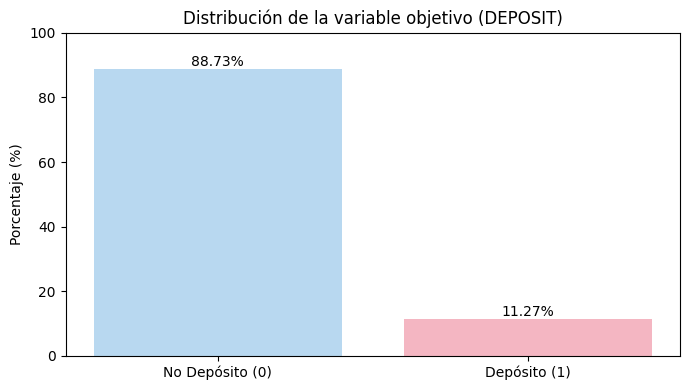


--- Tasa de suscripción por job ---
+-------------+--------+---------+------------------+
|          job|clientes|depositos|tasa_suscripcion_%|
+-------------+--------+---------+------------------+
|      student|     875|      275|             31.43|
|      retired|    1720|      434|             25.23|
|   unemployed|    1014|      144|              14.2|
|       admin.|   10422|     1352|             12.97|
|   management|    2924|      328|             11.22|
|      unknown|     330|       37|             11.21|
|   technician|    6743|      730|             10.83|
|self-employed|    1421|      149|             10.49|
|    housemaid|    1060|      106|              10.0|
| entrepreneur|    1456|      124|              8.52|
|     services|    3969|      323|              8.14|
|  blue-collar|    9254|      638|              6.89|
+-------------+--------+---------+------------------+


--- Tasa de suscripción por marital ---
+--------+--------+---------+------------------+
| marita

In [0]:
# Databricks notebook source
# ============================================================
# 1. LECTURA DEL DATASET Y LIMPIEZA DE COLUMNAS
# ============================================================
from pyspark.sql import functions as F
import matplotlib.pyplot as plt

DATA_PATH = "/Volumes/workspace/bigdata_daigreco/tp_final_data/bank-additional-full.csv"

# Lectura del CSV con separador punto y coma
df_raw = (
    spark.read
    .option("header", "true")
    .option("inferSchema", "true")
    .option("sep", ";")
    .csv(DATA_PATH)
)

# Reemplazar puntos y comillas en los nombres de las columnas para evitar errores de PySpark
clean_columns = [c.replace(".", "_").replace('"', '').strip() for c in df_raw.columns]

df = df_raw
for old_col, new_col in zip(df_raw.columns, clean_columns):
    df = df.withColumnRenamed(old_col, new_col)

# Renombrar y transformar el target ('y') a binario 0/1
df = df.withColumnRenamed("y", "DEPOSIT")
df = df.withColumn(
    "DEPOSIT",
    F.when(F.col("DEPOSIT") == "yes", 1).otherwise(0)
)

print(f"Registros cargados: {df.count():,}")
print(f"Cantidad de columnas: {len(df.columns)}")
df.printSchema()

# COMMAND ----------

# ============================================================
# 2. VISTA PREVIA Y CONTROL DE NULOS Y DUPLICADOS
# ============================================================
display(df.limit(10))

# Chequeo de valores nulos
null_counts = df.select([
    F.sum(F.col(c).isNull().cast("int")).alias(c)
    for c in df.columns
])

print("--- Nulos por columna ---")
display(null_counts)

# Chequeo de duplicados
total_rows = df.count()
unique_rows = df.dropDuplicates().count()
print(f"Registros totales: {total_rows:,}")
print(f"Registros duplicados: {total_rows - unique_rows:,}")

# COMMAND ----------

# ============================================================
# 3. DISTRIBUCIÓN DE LA VARIABLE OBJETIVO (DEPOSIT)
# ============================================================
target_distribution = (
    df.groupBy("DEPOSIT")
      .count()
      .withColumn(
          "percentage",
          F.round(F.col("count") / F.lit(total_rows) * 100, 2)
      )
      .orderBy("DEPOSIT")
)

display(target_distribution)

# Gráfico de distribución
target_pd = target_distribution.toPandas()
labels = ["No Depósito (0)", "Depósito (1)"]

plt.figure(figsize=(7, 4))
bars = plt.bar(
    labels,
    target_pd["percentage"],
    color=["#B8D8F0", "#F4B6C2"]
)

plt.title("Distribución de la variable objetivo (DEPOSIT)")
plt.ylabel("Porcentaje (%)")
plt.ylim(0, 100)

for bar, pct in zip(bars, target_pd["percentage"]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{pct:.2f}%",
        ha="center",
        fontsize=10
    )

plt.tight_layout()
plt.show()

# COMMAND ----------

# ============================================================
# 4. TASA DE SUSCRIPCIÓN SEGÚN VARIABLES CATEGÓRICAS
# ============================================================
categorical_cols = ["job", "marital", "education", "housing", "loan", "contact", "poutcome"]

for c in categorical_cols:
    print(f"\n--- Tasa de suscripción por {c} ---")
    (
        df.groupBy(c)
          .agg(
              F.count("*").alias("clientes"),
              F.sum("DEPOSIT").alias("depositos"),
              F.round(F.avg("DEPOSIT") * 100, 2).alias("tasa_suscripcion_%")
          )
          .orderBy(F.col("tasa_suscripcion_%").desc())
          .show()
    )